## BBM 409 - Programming Assignment 1

###  Mustafa Ege 2210356088

## Understanding Perceptron Learning Algorithm (100 points)

### 1. Data Loading and Exploration (5 points)
The goal of this task is to distinguish between two raisin varieties — **Kecimen** and **Besni** — based on geometric features extracted from their images.

The dataset contains **900 samples** and **7 numerical features**, each describing a shape-related property of the raisins:

- **Area:** Total number of pixels inside the raisin boundary  
- **MajorAxisLength:** Length of the longest axis of the raisin shape  
- **MinorAxisLength:** Length of the shortest axis  
- **Eccentricity:** Measures how elongated the raisin is (values closer to 1 indicate a more stretched shape)  
- **ConvexArea:** Area of the smallest convex polygon that can contain the raisin  
- **Extent:** Ratio of the raisin area to the area of its bounding box  
- **Perimeter:** The total boundary length of the raisin shape  

The target variable represents the **class label** of each sample:
- `Kecimen` — 450 samples  
- `Besni` — 450 samples  

The dataset is **balanced** and contains **no missing values**, making it ready for further preprocessing and model training without additional cleaning steps.

From the summary statistics, we can observe that the feature values (such as area, perimeter, and axis lengths) vary across a wide range, suggesting the raisins differ significantly in their size and shape. This indicates that **feature scaling** will likely be important before applying the perceptron, since features are on different scales (e.g., `Area` ranges in the tens of thousands, while `Extent` is between 0 and 1).

In [36]:
## Import necessary libraries
from ucimlrepo import fetch_ucirepo
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split 
import matplotlib.pyplot as plt

In [4]:
# fetch dataset
raisin = fetch_ucirepo(id=850)

# data (as pandas dataframes)
X_df = raisin.data.features
y_df = raisin.data.targets

# metadata
print(raisin.metadata)

# variable information
print(raisin.variables)

{'uci_id': 850, 'name': 'Raisin', 'repository_url': 'https://archive.ics.uci.edu/dataset/850/raisin', 'data_url': 'https://archive.ics.uci.edu/static/public/850/data.csv', 'abstract': 'Images of the Kecimen and Besni raisin varieties were obtained with CVS. A total of 900 raisins were used, including 450 from both varieties, and 7 morphological features were extracted.', 'area': 'Biology', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 900, 'num_features': 7, 'feature_types': ['Real', 'Integer'], 'demographics': [], 'target_col': ['Class'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2020, 'last_updated': 'Fri Jan 05 2024', 'dataset_doi': '10.24432/C5660T', 'creators': ['İ̇lkay Çinar', 'Murat Koklu', 'Sakir Tasdemir'], 'intro_paper': {'ID': 261, 'type': 'NATIVE', 'title': 'Kuru Üzüm Tanelerinin Makine Görüşü ve Yapay Zeka Yöntemleri Kullanılarak Sınıflandırılması', 'authors': 'İ̇lkay Çinar

In [5]:
# Preview first few rows
print("\nFirst 5 rows:")
print(X_df.head())

# Dataset info
print("\nDataset info:")
print(X_df.info())

# Summary statistics
print("\nSummary statistics:")
print(X_df.describe())

# Unique class labels
print("\nTarget variable distribution:")
print(y_df['Class'].value_counts())

# Check for missing values
print("\nMissing values per column:")
print(X_df.isnull().sum())



First 5 rows:
    Area  MajorAxisLength  MinorAxisLength  Eccentricity  ConvexArea  \
0  87524       442.246011       253.291155      0.819738       90546   
1  75166       406.690687       243.032436      0.801805       78789   
2  90856       442.267048       266.328318      0.798354       93717   
3  45928       286.540559       208.760042      0.684989       47336   
4  79408       352.190770       290.827533      0.564011       81463   

     Extent  Perimeter  
0  0.758651   1184.040  
1  0.684130   1121.786  
2  0.637613   1208.575  
3  0.699599    844.162  
4  0.792772   1073.251  

Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             900 non-null    int64  
 1   MajorAxisLength  900 non-null    float64
 2   MinorAxisLength  900 non-null    float64
 3   Eccentricity     900 non-null    float64
 4   Co

Convert the data frame into a Numpy array.

In [6]:
X_np = X_df.to_numpy()
y_np = y_df.to_numpy().ravel()

print("\nConverted to NumPy arrays:")
print("X shape:", X_np.shape)
print("y shape:", y_np.shape)


Converted to NumPy arrays:
X shape: (900, 7)
y shape: (900,)


### 2. Data Preprocessing (5 points)

#### Feature Scaling Techniques:
Feature scaling is needed on our data because the features like 'Area' and 'Eccentricity' are on completely on different scales one being around thousands and the other being smaller than 1. Features with large absolute values would dominate the distance/weighted sum calculation, preventing the perceptron from learning an optimal weight vector.

To ensure all features contribute proportionally to the decision boundary, we apply scaling.

We will explore three common techniques and select the one that yields the best training accuracy for the final model in the next section. The scaling methods we will try are below:

- **Standardization:** It scales the features to have a mean of 0 and a standard deviation of 1. Centers the data and avoids features with large variances disproportionately influencing the model's convergence.
- **Min-Max Scaling:** It scales the features to a fixed range, typically between 0 and 1. Ensures all features have an identical scale, which can be useful when weights need to be small and constrained.
- **Robust Scaling:** Scales features using the Median and the Interquartile Range (IQR) (the difference between the 75th and 25th percentiles). This method is robust to outliers, as the median and IQR are less affected by extreme values than the mean and standard deviation are.

The labels of raisins are in categorical format as Besni and Kecimen, we first need to transform those labels into -1 and +1 for perceptron algorithm which requires class labels of -1, +1.

In [7]:
# Perceptron requires labels in {-1, 1}. Transform y_np:
# Class 0 (Besni) -> -1
# Class 1 (Kecimen) -> +1

# Check the unique classes before transformation
print("Original unique classes:", np.unique(y_np)) 

# Direct mapping from strings to Perceptron labels (-1, +1)
label_mapping = {'Besni': -1, 'Kecimen': 1} 

# Apply the mapping to create the final transformed labels
y_transformed = np.array([label_mapping[label] for label in y_np])

# Final verification
print("Transformed unique classes:", np.unique(y_transformed))

Original unique classes: ['Besni' 'Kecimen']
Transformed unique classes: [-1  1]


#### Training and Validation Split

When building a machine learning model, it is important to evaluate its performance not only on the data it was trained on but also on unseen data.  
To achieve this, we divide the dataset into two parts:

- Training set — used by the perceptron to learn patterns and adjust weights. Generally 80% of the data.
- Validation set — used to evaluate how well the trained model performs on new, unseen samples. Generally 20% of the data.

If we only evaluate the model on the training data, we might get a perfect result because the model could simply memorize patterns too specific to that data and the noise and it is called **overfitting**.
By testing on the validation set, we can measure how effectively the model can make predictions on data it has never seen before. which we call **generalization**. The reason behind this is perceptron will only get trained by the training set, it will never see validation set and the y values on it. Then when we test the trained model we will see if the perceptron can make good predictions on brand new data.

In [8]:
# Split the dataset into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X_np, y_transformed, test_size=0.2, random_state=23, shuffle=True
)

# Print the shapes of the resulting sets
print("Shape of X_train:", X_train.shape)
print("Shape of X_test:", X_test.shape)
print("Shape of Y_train:", y_train.shape) 
print("Shape of Y_test:", y_test.shape)   

Shape of X_train: (720, 7)
Shape of X_test: (180, 7)
Shape of Y_train: (720,)
Shape of Y_test: (180,)


Before applying feature scaling, we first will splitted the data. This ensures that the scaling process does not see information from the validation data, which would lead to data leakage.

Below we will define the preprocessing methods, then use the scaled data in the next section and see the accuracy results of all methods.

In [9]:
def standardize(X_train, X_test):
    # X_scaled = (X - mean) / std_dev   
    #     
    # Calculate mean and standard deviation
    mean_train = np.mean(X_train, axis=0)
    std_train = np.std(X_train, axis=0)

    # avoid division by zero
    std_train_safe = np.where(std_train == 0, 1e-8, std_train)

    # apply to both sets 
    x_train_standardize = (X_train - mean_train) / std_train_safe
    x_test_standardize = (X_test - mean_train) / std_train_safe

    return x_train_standardize, x_test_standardize


In [10]:
def minmax_scale(X_train, X_test):
    # X_scaled = (X - X_min) / (X_max - X_min)
    
    # calculate min and max only from the training data
    min_train = np.min(X_train, axis=0)
    max_train = np.max(X_train, axis=0)
    
    # Calculate the range (denominator)
    range_train = max_train - min_train
    
    # avoid division by zero
    range_train[range_train == 0] = 1e-8 
    
    # apply to both sets 
    X_train_minmax_scaled = (X_train - min_train) / range_train
    X_test_minmax_scaled = (X_test - min_train) / range_train
    
    return X_train_minmax_scaled, X_test_minmax_scaled

In [11]:
def robust_scale(X_train, X_test):
    # X_scaled = (X - Median) / IQR

    # calculate median
    median_train = np.median(X_train, axis=0)
    
    # calculate Q1 (25th percentile) and Q3 (75th percentile)
    Q1_train = np.percentile(X_train, 25, axis=0)
    Q3_train = np.percentile(X_train, 75, axis=0)
    
    # calculate the Interquartile Range (IQR)
    IQR_train = Q3_train - Q1_train
    
    # avoid division by zero
    IQR_train[IQR_train == 0] = 1e-8
    
    # apply to both sets 
    X_train_robust_scaled = (X_train - median_train) / IQR_train
    X_test_robust_scaled = (X_test - median_train) / IQR_train
    
    return X_train_robust_scaled, X_test_robust_scaled

### 3. Implementing Perceptron for Binary Classification (20 points)

Explain the reason behind the application of perceptron learning algorithm on this type of data. If the dataset had two classes but was not linearly separable, how would the perceptron's performance change? Briefly explain.

####  Implement Percepton Learning Algorithm

In [26]:
class Perceptron:
    def __init__(self, learning_rate=0.01, n_epochs=50, random_state=20):
        # Initialize the model parameters (weights, bias) and hyperparameters
        self.lr = learning_rate
        self.n_epochs = n_epochs
        # Setting random_state for reproducibility in NumPy's random functions
        self.random_state = random_state 
        self.weights = None
        self.bias = None
        self.errors_ = []  # To store misclassification count per epoch

    def fit(self, X, y):
        rgen = np.random.RandomState(self.random_state)
        
        # Initialize weights to small random numbers, and bias to 0.0
        # X.shape[1] is the number of features
        self.weights = rgen.normal(loc=0.0, scale=0.01, size=X.shape[1])
        self.bias = 0.0
        
        # Iterate over epochs
        for _ in range(self.n_epochs):
            errors = 0
            # Iterate over each training sample
            for xi, target in zip(X, y):
              
                # Check for misclassification: 
                # The update only occurs if y_i and prediction have different signs
                prediction = self.predict(xi)
                
                if target != prediction:
                    # Target is the true label (y_i in {-1, 1})
                    # xi is the input vector

                    # Calculate prediction: 
                    update = self.lr * target # update is eta * y_i

                    # Update weights: w <- w + eta * y_i * x_i 
                    self.weights += update * xi
                    
                    # Update bias: b <- b + eta * y_i 
                    self.bias += update
                    
                    errors += 1
            
            self.errors_.append(errors)
            
            # Add an early stop if errors == 0 (convergence)
            if errors == 0:
                print("Model converged")
                break
                
        return self

    def weighted_sum(self, X):
        # Calculate the weighted sum z = w^T * x + b
        # The result must be a 1D array of z values (one for each row in X)
        return np.dot(X, self.weights) + self.bias

    def predict(self, X):
        # Determine the class label based on the sign of z (Step Function)
        return np.where(self.weighted_sum(X) >= 0.0, 1, -1)

In the perceptron model above, and perceptron model in general has several parameters that control how it learns from data.  

`Learnable parameters` are initialized once and then iteratively adjusted during the training process to minimize classification errors.

 **1. Weights (self.weights)**
- Represent the strength of the connection between each input feature and the output.
- Initially set to small random values so that not all features learn the same way.
- During training, they are updated whenever a misclassification occurs using the rule: w = w + eta * y_i * x_i
- The weights determine the orientation of the hyperplane that separates the two classes.

 **2. Bias (self.bias)**
- A constant term added to the weighted sum to shift the decision boundary.
- Updated similarly to the weights when a misclassification occurs: b = b + eta * y_i
- Allows the hyperplane to move away from the origin, improving flexibility in classification.

`Hyperparameters` control the behavior and optimization process of the algorithm but are not learned from the data itself.

 1. **Learning Rate (learning_rate)**
- Controls the step size for each update to the weights and bias.
- If eta is too large updates overshoot the optimal boundary and cause oscillation.
- If eta is too small training becomes very slow and might get stuck before convergence.
- 0.001–0.1 depending on the dataset and scaling.

 **2. Number of Epochs (n_epochs)**
- Specifies how many passes the algorithm makes over the entire training dataset.
- Each epoch processes all training samples once.
- A higher number gives the model more chances to learn, but if too high, it may lead to unnecessary computation or overfitting.

 **3. Random State (random_state)**
- Used to seed the random number generator (np.random.RandomState).
- Ensures that weight initialization is the same each time the code run so we get consistent results everytime we rerun. (reproducability)

By tuning these parameters, we can control the speed, stability, and accuracy of the Perceptron’s training process.


#### Accuracy implementation

In [27]:
def calculate_accuracy(y_true, y_pred):
    """
    Calculates the accuracy score.
    y_true: true labels (NumPy array)
    y_pred: predicted labels (NumPy array)
    """
    # Compare true labels and predicted labels. 
    # np.sum counts the number of 'True' comparisons (correct predictions).
    correct_predictions = np.sum(y_true == y_pred)
    total_samples = len(y_true)
    
    accuracy = correct_predictions / total_samples
    return accuracy

#### Train the Perceptron

In [14]:
## Train the Perceptron model on the training set. You will use all features in the first classification.

#### Prediction on Training Data

In [28]:
# Apply standardization
X_train_standardize, X_test_standardize = standardize(X_train, X_test)

# Instantiate and train Perceptron
ppn_standardize = Perceptron() 
ppn_standardize.fit(X_train_standardize, y_train) 

# Predict and evaluate
y_train_pred_standardize = ppn_standardize.predict(X_train_standardize)
accuracy_standardize = calculate_accuracy(y_train, y_train_pred_standardize)

print(f"Standardized Training Accuracy: {accuracy_standardize:.4f}")

Standardized Training Accuracy: 0.8333


In [29]:
y_test_pred_standardize = ppn_standardize.predict(X_test_standardize)
accuracy_minmax = calculate_accuracy(y_test, y_test_pred_standardize)

print(f"Standardized test Accuracy: {accuracy_minmax:.4f}")

Standardized test Accuracy: 0.8389


In [17]:
# Apply Min-Max Scaling
X_train_minmax, X_test_minmax = minmax_scale(X_train, X_test)

# Instantiate and train Perceptron with Min-Max scaled data
# Use your desired hyperparameters
ppn_minmax = Perceptron() 
ppn_minmax.fit(X_train_minmax, y_train) 

# Predict and evaluate
y_train_pred_minmax = ppn_minmax.predict(X_train_minmax)
accuracy_minmax = calculate_accuracy(y_train, y_train_pred_minmax)

print(f"Min-Max Training Accuracy: {accuracy_minmax:.4f}")

Min-Max Training Accuracy: 0.8139


In [18]:
y_test_pred_minmax = ppn_minmax.predict(X_test_minmax)
accuracy_minmax = calculate_accuracy(y_test, y_test_pred_minmax)

print(f"Min-Max test Accuracy: {accuracy_minmax:.4f}")

Min-Max test Accuracy: 0.8333


In [19]:
# Apply Robust Scaling
X_train_robust, X_test_robust = robust_scale(X_train, X_test)

# Instantiate and train Perceptron with Robust scaled data
# Use your desired hyperparameters
ppn_robust = Perceptron() 
ppn_robust.fit(X_train_robust, y_train) 

# Predict and evaluate
y_train_pred_robust = ppn_robust.predict(X_train_robust)
accuracy_robust = calculate_accuracy(y_train, y_train_pred_robust)

print(f"Robust Scaled Training Accuracy: {accuracy_robust:.4f}")

Robust Scaled Training Accuracy: 0.8403


In [20]:
y_test_pred_robust = ppn_robust.predict(X_test_robust)
accuracy_robust = calculate_accuracy(y_test, y_test_pred_robust)

print(f"Robust Scaled test Accuracy: {accuracy_robust:.4f}")

Robust Scaled test Accuracy: 0.8389


In [ ]:
def train_perceptron_hyperparameters(X_train, y_train):
    # Use a range of values for learning rate and epochs
    etas = [0.1, 0.01, 0.001, 0.0001]
    epochs = [10, 50, 100, 500, 1000, 10000] 

    best_accuracy = 0.0
    best_params = {}
    best_ppn = None
    results_list = []
    print("--- Starting Hyperparameter Search ---")

    for lr in etas:
        for epoch in epochs:
            # 1. Instantiate the Perceptron
            # Use a fixed random_state for consistency
            ppn_candidate = Perceptron(learning_rate=lr, n_epochs=epoch)
            
            # 2. Train the model
            ppn_candidate.fit(X_train, y_train)
            
            # 3. Predict on training data
            y_pred_train_candidate = ppn_candidate.predict(X_train)
            
            
            # 4. Calculate Accuracy (using the already defined function)
            current_accuracy = calculate_accuracy(y_train, y_pred_train_candidate)
            
            results_list.append({
                'LR': lr, 
                'Epochs': epoch, 
                'Accuracy': current_accuracy
            })

            print(f"LR: {lr:.4f}, Epochs: {epoch:4d} -> Acc: {current_accuracy:.4f}")
            
            # 5. Track the best model
            if current_accuracy > best_accuracy:
                best_accuracy = current_accuracy
                best_params = {'learning_rate': lr, 'n_epochs': epoch}
                best_ppn = ppn_candidate
        print("\n")
    print("--- Search Complete ---")
    print(f"Best Training Accuracy: {best_accuracy:.4f} found with parameters: {best_params}")
    return best_ppn, results_list

In [33]:
best_ppn, search_results = train_perceptron_hyperparameters(X_train_robust, y_train)

--- Starting Hyperparameter Search on Robust Scaled Data ---
LR: 0.1000, Epochs:   10 -> Acc: 0.8389
LR: 0.1000, Epochs:   50 -> Acc: 0.8514
LR: 0.1000, Epochs:  100 -> Acc: 0.8375
LR: 0.1000, Epochs:  500 -> Acc: 0.8139
LR: 0.1000, Epochs: 1000 -> Acc: 0.8389
LR: 0.1000, Epochs: 10000 -> Acc: 0.8347


LR: 0.0100, Epochs:   10 -> Acc: 0.8347
LR: 0.0100, Epochs:   50 -> Acc: 0.8264
LR: 0.0100, Epochs:  100 -> Acc: 0.8417
LR: 0.0100, Epochs:  500 -> Acc: 0.8264
LR: 0.0100, Epochs: 1000 -> Acc: 0.8569
LR: 0.0100, Epochs: 10000 -> Acc: 0.8208


LR: 0.0010, Epochs:   10 -> Acc: 0.8014
LR: 0.0010, Epochs:   50 -> Acc: 0.8431
LR: 0.0010, Epochs:  100 -> Acc: 0.8514
LR: 0.0010, Epochs:  500 -> Acc: 0.8111
LR: 0.0010, Epochs: 1000 -> Acc: 0.8250
LR: 0.0010, Epochs: 10000 -> Acc: 0.8417


LR: 0.0001, Epochs:   10 -> Acc: 0.8042
LR: 0.0001, Epochs:   50 -> Acc: 0.8361
LR: 0.0001, Epochs:  100 -> Acc: 0.8375
LR: 0.0001, Epochs:  500 -> Acc: 0.8125
LR: 0.0001, Epochs: 1000 -> Acc: 0.8597
LR: 0.0001

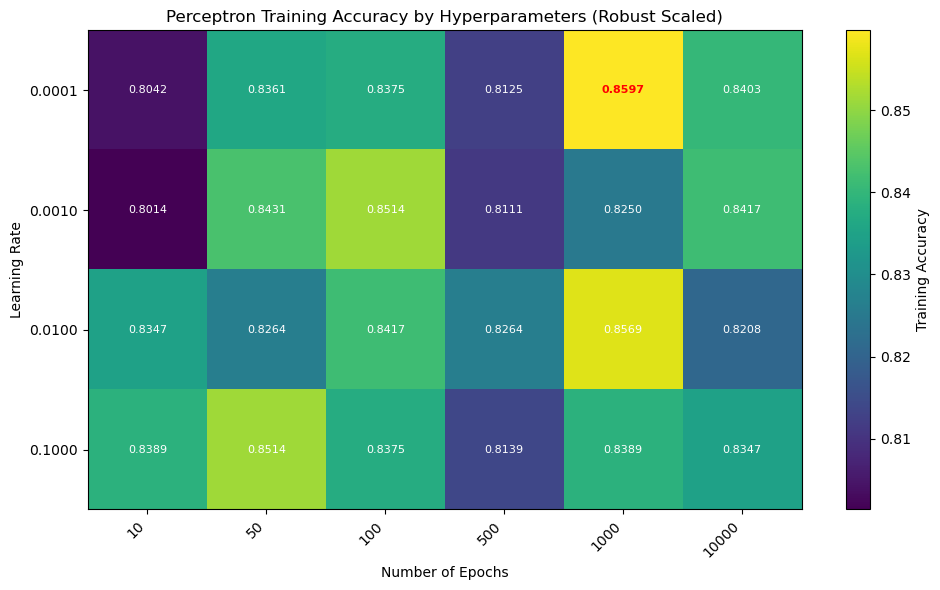

In [39]:
# 1. Create DataFrame directly from the returned list
df = pd.DataFrame(search_results)

# 2. Pivot the DataFrame to create the grid for the heatmap
pivot_table = df.pivot(index='LR', columns='Epochs', values='Accuracy')

# 3. Identify the best accuracy for highlighting
best_acc = df['Accuracy'].max()

# 4. Generate the heatmap plot
plt.figure(figsize=(10, 6))
plt.imshow(pivot_table, cmap='viridis', aspect='auto')

# Labels and Ticks
plt.colorbar(label='Training Accuracy')
plt.xlabel('Number of Epochs')
plt.ylabel('Learning Rate')
plt.title('Perceptron Training Accuracy by Hyperparameters (Robust Scaled)')

# Set ticks and labels for Epochs (X-axis)
epochs_labels = pivot_table.columns.tolist()
plt.xticks(np.arange(len(epochs_labels)), epochs_labels, rotation=45, ha='right')

# Set ticks and labels for LR (Y-axis)
lr_labels = pivot_table.index.tolist()
lr_labels_str = [f'{lr:.4f}' for lr in lr_labels]
plt.yticks(np.arange(len(lr_labels)), lr_labels_str) 

# 5. Add text annotations for accuracy values
for i in range(len(lr_labels)):
    for j in range(len(epochs_labels)):
        acc = pivot_table.iloc[i, j]
        # Highlight the best accuracy
        color = 'red' if acc == best_acc else 'white'
        fontweight = 'bold' if acc == best_acc else 'normal'
        plt.text(j, i, f'{acc:.4f}', ha='center', va='center', color=color, fontsize=8, fontweight=fontweight)

plt.tight_layout()

plt.show()

Discuss how the choice of learning rate and the number of epochs might affect the
training process. What happens with a very small or very large learning rate?

In [22]:
y_train_pred = best_ppn.predict(X_train_robust)
y_test_pred = best_ppn.predict(X_test_robust)

Answer the Guiding Questions:
1. What does accuracy tell us about the performance of the model?
2. Why is accuracy sometimes not enough, especially in cases where the data is imbalanced? Explain a scenario where a high accuracy might be misleading.
3. In what types of problems is precision more important than recall?
4. In what cases is recall more critical?
5. When is the F1 score a better measure than accuracy? What are the limitations of using F1 score alone?

### 4. Evaluating Perceptron for Binary Classification (25 points)

#### Prediction on Validation Data

#### Evaluate the model's performance on the test set by calculating accuracy. Print classification report and confusion matrix

Answer the Guiding Questions:
1. What does accuracy tell us about the performance of the model?
2. Why is accuracy sometimes not enough, especially in cases where the data is imbal-
anced? Explain a scenario where a high accuracy might be misleading.

In [23]:
def calculate_metrics(y_true, y_pred):
    """
    Calculates Accuracy, Precision, Recall, and F1 Score.
    The labels y_true and y_pred must be in the format {-1, +1}.
    """
    # Convert to 1D arrays if necessary
    y_true = y_true.flatten()
    y_pred = y_pred.flatten()

    # Define the Positive class as +1, and Negative class as -1 (Besni)
    
    # Calculate the Confusion Matrix Components
    
    TP = np.sum((y_true == 1) & (y_pred == 1))
    TN = np.sum((y_true == -1) & (y_pred == -1))
    FP = np.sum((y_true == -1) & (y_pred == 1))
    FN = np.sum((y_true == 1) & (y_pred == -1))
    
    total_samples = len(y_true)
    
    #  Calculate Metrics 
    
    # Accuracy 
    accuracy = (TP + TN) / total_samples
    
    # Precision 
    precision = TP / (TP + FP) if (TP + FP) > 0 else 0
    
    # Recall 
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0
    
    # F1 Score
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
    
    # Support: The number of actual occurrences of the class (+1).
    support = TP + FN
    
    return accuracy, precision, recall, f1, support

In [24]:
# Calculate and print metrics

accuracy_train, precision_train, recall_train, f1_train, _ = calculate_metrics(y_train.flatten(), y_train_pred)
print("========== Training Metrics ==========")
print(f"Training Accuracy:    {accuracy_train:.4f}")
print(f"Training Precision:   {precision_train:.4f}")
print(f"Training Recall:      {recall_train:.4f}")
print(f"Training F1 Score:    {f1_train:.4f}")
print("======================================\n")

accuracy_test, precision_test, recall_test, f1_test, _ = calculate_metrics(y_test.flatten(), y_test_pred)
print("======== Validation Metrics ==========")
print(f"Validation Accuracy:  {accuracy_test:.4f}")
print(f"Validation Precision: {precision_test:.4f}")
print(f"Validation Recall:    {recall_test:.4f}")
print(f"Validation F1 Score:  {f1_test:.4f}")
print("======================================")

========== Training Metrics ==========
Training Accuracy:    0.8597
Training Precision:   0.8818
Training Recall:      0.8244
Training F1 Score:    0.8521

======== Validation Metrics ==========
Validation Accuracy:  0.8444
Validation Precision: 0.8485
Validation Recall:    0.8660
Validation F1 Score:  0.8571


 *Carefully examine the **classification report** obtained after the classification process.  
Analyze each metric in the report — such as **accuracy, precision, recall, f1-score, and support** — and interpret the performance of your model.*  

*For each metric, explain:*  
*- What this value represents in the context of your model,*  
*- What it means if the value is high or low, and*  
*- Which aspects of your model are strong or weak based on this metric.*


### 5. Visualization of the Hyperplane (40 + 5 points)

In this section, you will explore how the Perceptron Learning Algorithm forms the decision boundary (or hyperplane) that separates the two classes. To be able to do that
you will reduce the feature space to two dimensions, train the Perceptron on the selected
features, and visualize the hyperplane. The goal is to understand how the Perceptron
changes the decision boundary as the data changes, and how it adapts based on the
features used.

#### Step 1: Feature Selection Using Correlation Analysis (10 points)

1. Correlation Analysis: One effective way to reduce the number of features is by
analyzing the correlation between them. Highly correlated features may provide re-
dundant information, so you can select two less correlated features for visualization.
2. Compute the correlation matrix: Analyze the relationship between the all features to identify pairs of features with low
correlation.

In [25]:
# Compute the correlation matrix
correlation_matrix =
# Display the correlation matrix as a heatmap

SyntaxError: invalid syntax (3345476196.py, line 2)

3. Choose two features: Based on the correlation analysis, select two features that are
least correlated (e.g., variance and skewness) to visualize the Perceptron’s decision
boundary.

In [ ]:
# Select two features (for example (Area and ConvexArea) and two more pair) according to their correlation
# Select these features from the original feature set
# Find a pair of features such that the separation between classes is at its highest level. Similarly, find a pair of features such that the separation between classes is at its lowest level. Finally, find the pair of features with average separability.
# Split the selected features into training and validation sets if not done yet

#### Step 2: Train the Perceptron on Selected Features (10 points)

1. Retrain the Perceptron: After selecting two features, train the Perceptron using
only these two features. Use the same training and evaluation process as before,
but now the model will work in a two-dimensional feature space.

In [ ]:
## Train the Perceptron model on the training set.

# Predicting on the training data
print("Training Accuracy:", accuracy_train)

2. Visualize the decision boundary (hyperplane): Once the Perceptron is trained, plot
the decision boundary (hyperplane) to see how the Perceptron separates the two
classes in 2D.

In [ ]:
# Function to plot the decision boundary
def plot_decision_boundary(X, y, model):

# Plot the decision boundary using the selected features and trained model

#### Step 3: Experiment with Different Features (10 points)

After visualizing the decision boundary for one pair of features, try selecting different
combinations of features (e.g., Area and MaxorAxisLength) and retrain the Perceptron. Compare
how the hyperplane changes with different features. This helps in understanding how the
Perceptron’s decision-making process adapts to different feature sets.

* Answer the guiding questions:  
1. How does the decision boundary change when you use different pairs of features?  
2. Can you find a pair of features that leads to better separation between the two classes? Also explain why this feature pair causes the better separation.  
3. If the classes cannot be linearly separated in a given pair of features, can we still talk about a linear relationship between them? Explain your reasoning.


#### Bonus Step 4: Incrementally Add Data (+ 5 points)

1. Visualizing Incremental Learning: Another experiment to help understand the behavior of the Perceptron is to add data incrementally. Start with a small portion of the dataset and progressively add more data points to train the Perceptron.

* For example, draw the decision boundary using the first 5% of the data, then increase it by 10% increments, continuing the process until the entire dataset is used, and draw the decision boundary at each step.


2. Observe how the decision boundary shifts: As you add more data, observe how the
hyperplane shifts and adapts to new points. This will help you understand how the
Perceptron continuously adjusts the boundary to separate the classes.

#### Step 6: Fisher’s Linear Discriminant Projection (10 points)
* In this step, you will implement Fisher’s Linear Discriminant (LD) to project the
dataset onto a 1D space and visualize the distribution of the two classes in the projected
space using a histogram. The goal of Fisher’s LD is to find the direction in the feature
space that maximizes the separation between two classes while minimizing the variance
within each class. This technique projects the data onto a single dimension where the
separation between the classes is optimized.

In [ ]:
def fisher_ld_projection(X, y):
    """Compute Fisher's Linear Discriminant projection direction."""

def project_data(X, direction):
    """Project data onto the Fisher LD direction."""

In [ ]:
direction = fisher_ld_projection()

# Project the data onto the Fisher LD direction
projected_data = project_data()

### Visualizations
#### 2D Feature Space (Optional but Recommended)
* While not mandatory, it can be highly instructive to visualize the projection direction computed by Fisher’s LD in the original 2D feature space. This will help you understand how the data is being projected onto a 1D space and why this direction is optimal for class separation.

In [ ]:
# Plot the 2D data with the projection direction

# Hint: You can use plt.scatter() to plot the 2D data with its features
# You can find the mean of the entire dataset for placing the direction vector
# Hint: You can use plt.quiver() method to visualize the direction vector
# Do not forget to scale the direction vector to visualize it properly
scale = 4 # Adjust this to control the length of the direction line

### 1D Projected Space (Required)
* Plot a histogram showing the distribution of the
projected data for each class in the 1D space. The histogram will help you visualize
how well the two classes are separated by the Fisher’s LD projection.

In [ ]:
# Plot the histogram of the projected data

Answer the guiding questions:
1. How well does Fisher’s LD separate the two classes in the 1D projected space?
2. Compare the separation of the two classes in the original 2D space (used in the
Perceptron) versus the 1D Fisher’s LD projection. What do you observe about the
class distributions in these spaces?